In [1]:
import torch

# Kiểm tra xem PyTorch có nhận diện được GPU (CUDA) không (Sẽ trả về True hoặc False)
print("GPU có sẵn không:", torch.cuda.is_available())

# In ra số lượng GPU đang có mặt trên máy chủ
print("Số lượng GPU:", torch.cuda.device_count())

# In ra tên chính xác của Card đồ họa (Ví dụ: Tesla T4, RTX 3090...)
if torch.cuda.is_available():
    print("Tên GPU:", torch.cuda.get_device_name(0))

GPU có sẵn không: True
Số lượng GPU: 1
Tên GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
!pip install torchinfo


[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Tiền xử lí dữ liệu



- Tăng cường dữ liệu (Data Augmentation):

RandomCrop (cắt ngẫu nhiên)

RandomHorizontalFlip (lật ảnh ngang)

- Chuẩn hóa (Normalization) dựa trên thông số đặc trưng của CIFAR-10:

Mean (0.4914, 0.4822, 0.4465)

Std (0.2023, 0.1994, 0.2010).





In [3]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Định nghĩa các bước biến đổi dữ liệu (Transforms)
train_transform = transforms.Compose([
    # Tăng cường dữ liệu (Data Augmentation) cho tập Train nhằm chống Overfitting
    transforms.RandomCrop(32, padding=4),     # Cắt ngẫu nhiên dời 4 pixel
    transforms.RandomHorizontalFlip(),        # Lật ảnh ngẫu nhiên theo chiều ngang

    transforms.ToTensor(),                    # Chuyển ảnh PIL thành Tensor (0 -> 1)

    # Chuẩn hóa (Normalization) theo trung bình và độ lệch chuẩn của tập CIFAR-10
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                         std=[0.2023, 0.1994, 0.2010])
])

val_transform = transforms.Compose([
    # Tập Validation/Test KHÔNG dùng Augmentation, chỉ chuyển Tensor và Chuẩn hóa
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                         std=[0.2023, 0.1994, 0.2010])
])

# 2. Tải Dataset
trainset = datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
testset = datasets.CIFAR10(root='./data', train=False, download=True, transform=val_transform)

# 3. Khởi tạo DataLoader
trainloader = DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
testloader = DataLoader(testset, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

Files already downloaded and verified
Files already downloaded and verified


# Mô hình

In [4]:
import torch
import torch.nn as nn
import torchvision.models as models
from torchinfo import summary

# Define input_size for CIFAR-10 images (3 channels, 32x32 pixels)
input_size = (1, 3, 32, 32)

# ==========================================
# 1. VGG-11
# ==========================================
def get_vgg11_cifar10():
    model = models.vgg11(weights=None)

    # Vô hiệu hóa lớp AdaptiveAvgPool2d để giữ nguyên kích thước 1x1
    model.avgpool = nn.Identity()

    model.classifier = nn.Sequential(
        nn.Linear(512 * 1 * 1, 512),
        nn.ReLU(True),
        nn.Dropout(p=0.5),
        nn.Linear(512, 10)
    )
    return model

# ==========================================
# 2. ResNet-18
# ==========================================
def get_resnet18_cifar10():
    model = models.resnet18(weights=None)
    # Sửa lớp Conv1: kernel 7x7 stride 2 -> 3x3 stride 1
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    # Xóa sổ lớp MaxPool đầu tiên
    model.maxpool = nn.Identity()
    # Phân loại 10 class
    model.fc = nn.Linear(model.fc.in_features, 10)
    return model

# ==========================================
# 3. GoogLeNet (Inception)
# ==========================================
def get_googlenet_cifar10():
    # aux_logits=False để tắt các nhánh phân loại phụ (tránh lỗi với ảnh 32x32)
    model = models.googlenet(weights=None, aux_logits=False, transform_input=False)

    # Sửa lớp Conv đầu tiên của GoogLeNet: 7x7 stride 2 -> 3x3 stride 1
    model.conv1.conv = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)

    # Xóa MaxPool đầu tiên để giữ nguyên kích thước đặc trưng
    model.maxpool1 = nn.Identity()

    # Phân loại 10 class
    model.fc = nn.Linear(model.fc.in_features, 10)
    return model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vgg_model = get_vgg11_cifar10().to(device)
resnet_model = get_resnet18_cifar10().to(device)
googlenet_model = get_googlenet_cifar10().to(device)

print("Đã khởi tạo thành công 3 mô hình: VGG-11, ResNet-18 và GoogLeNet!")



c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\models\googlenet.py:47: FutureWarning: The default weight initialization of GoogleNet will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(


Đã khởi tạo thành công 3 mô hình: VGG-11, ResNet-18 và GoogLeNet!


Kiến trúc mô hình VGG-11

In [5]:
summary(vgg_model, input_size=input_size, device=device)

Layer (type:depth-idx)                   Output Shape              Param #
VGG                                      [1, 10]                   --
├─Sequential: 1-1                        [1, 512, 1, 1]            --
│    └─Conv2d: 2-1                       [1, 64, 32, 32]           1,792
│    └─ReLU: 2-2                         [1, 64, 32, 32]           --
│    └─MaxPool2d: 2-3                    [1, 64, 16, 16]           --
│    └─Conv2d: 2-4                       [1, 128, 16, 16]          73,856
│    └─ReLU: 2-5                         [1, 128, 16, 16]          --
│    └─MaxPool2d: 2-6                    [1, 128, 8, 8]            --
│    └─Conv2d: 2-7                       [1, 256, 8, 8]            295,168
│    └─ReLU: 2-8                         [1, 256, 8, 8]            --
│    └─Conv2d: 2-9                       [1, 256, 8, 8]            590,080
│    └─ReLU: 2-10                        [1, 256, 8, 8]            --
│    └─MaxPool2d: 2-11                   [1, 256, 4, 4]            -

Kiến trúc mô hình Resnet-18

In [6]:
summary(resnet_model, input_size=input_size, device=device)

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 10]                   --
├─Conv2d: 1-1                            [1, 64, 32, 32]           1,728
├─BatchNorm2d: 1-2                       [1, 64, 32, 32]           128
├─ReLU: 1-3                              [1, 64, 32, 32]           --
├─Identity: 1-4                          [1, 64, 32, 32]           --
├─Sequential: 1-5                        [1, 64, 32, 32]           --
│    └─BasicBlock: 2-1                   [1, 64, 32, 32]           --
│    │    └─Conv2d: 3-1                  [1, 64, 32, 32]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 32, 32]           128
│    │    └─ReLU: 3-3                    [1, 64, 32, 32]           --
│    │    └─Conv2d: 3-4                  [1, 64, 32, 32]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 32, 32]           128
│    │    └─ReLU: 3-6                    [1, 64, 32, 32]           --
│

Kiến trúc mô hình GoogleNet

In [7]:
summary(googlenet_model, input_size=input_size, device=device)

Layer (type:depth-idx)                   Output Shape              Param #
GoogLeNet                                [1, 10]                   --
├─BasicConv2d: 1-1                       [1, 64, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 64, 32, 32]           1,728
│    └─BatchNorm2d: 2-2                  [1, 64, 32, 32]           128
├─Identity: 1-2                          [1, 64, 32, 32]           --
├─BasicConv2d: 1-3                       [1, 64, 32, 32]           --
│    └─Conv2d: 2-3                       [1, 64, 32, 32]           4,096
│    └─BatchNorm2d: 2-4                  [1, 64, 32, 32]           128
├─BasicConv2d: 1-4                       [1, 192, 32, 32]          --
│    └─Conv2d: 2-5                       [1, 192, 32, 32]          110,592
│    └─BatchNorm2d: 2-6                  [1, 192, 32, 32]          384
├─MaxPool2d: 1-5                         [1, 192, 16, 16]          --
├─Inception: 1-6                         [1, 256, 16, 16]          --
│

# **Cấu hình train:**

Epoch: 100

Learning Rate = 0,001

Automatic Mixed Precision (AMP) để tăng tốc độ huấn luyện.

Early Stopping: Patience = 10 epoch


**Loss Function và Optimizer:**

Loss: CrossEntropyLoss.

Optimizer: Adam (LR=0,001)

Scheduler: ReduceLROnPlateau tự động giảm Learning Rate đi 10 lần nếu độ chính xác không tăng sau 5 chu kỳ.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import time

# Sử dụng GradScaler cho Mixed Precision (Tăng tốc độ train trên RTX)
scaler = torch.cuda.amp.GradScaler()

def train_and_evaluate(model, model_name, train_loader, val_loader, device, epochs=100, patience=10, min_delta=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # ReduceLROnPlateau
    # factor=0.1 nghĩa là giảm LR đi 10 lần nếu không cải thiện
    # patience=5: Chờ 5 epoch không cải thiện thì mới giảm LR
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.1, patience=5)

    # Các list lưu trữ toàn bộ lịch sử
    train_acc_history = []
    train_loss_history = []
    val_acc_history = []
    val_loss_history = []

    best_val_acc = 0.0
    epochs_no_improve = 0

    # Bấm giờ tổng toàn bộ quá trình train
    total_start_time = time.time()

    for epoch in range(epochs):
        start_time = time.time()

        # ==========================================
        # 1. HUẤN LUYỆN (TRAIN)
        # ==========================================
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()

            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item()

            with torch.no_grad():
                _, predicted = outputs.max(1)
                train_total += labels.size(0)
                train_correct += predicted.eq(labels).sum().item()

        # ==========================================
        # 2. KIỂM THỬ (VALIDATION)
        # ==========================================
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        # ==========================================
        # 3. THỐNG KÊ & CẬP NHẬT LEARNING RATE
        # ==========================================
        epoch_train_loss = train_loss / len(train_loader)
        epoch_train_acc = train_correct / train_total
        epoch_val_loss = val_loss / len(val_loader)
        epoch_val_acc = val_correct / val_total

        # Lưu vào lịch sử
        train_loss_history.append(epoch_train_loss)
        train_acc_history.append(epoch_train_acc)
        val_loss_history.append(epoch_val_loss)
        val_acc_history.append(epoch_val_acc)

        # Báo cáo cho Scheduler biết Val Acc hiện tại để nó quyết định có giảm LR không
        scheduler.step(epoch_val_acc)
        # Lấy Learning Rate hiện tại để in ra màn hình
        current_lr = optimizer.param_groups[0]['lr']

        end_time = time.time()
        print(f"Epoch [{epoch+1:03d}/{epochs}] | LR: {current_lr:.6f} | "
              f"Train Loss: {epoch_train_loss:.4f} - Acc: {epoch_train_acc:.4f} | "
              f"Val Loss: {epoch_val_loss:.4f} - Acc: {epoch_val_acc:.4f} | "
              f"Thời gian: {end_time - start_time:.1f}s")

        # ==========================================
        # 4. KIỂM TRA EARLY STOPPING & LƯU MÔ HÌNH
        # ==========================================
        # Chỉ lưu khi cải thiện tối thiểu min_delta (0.1%)
        if epoch_val_acc > (best_val_acc + min_delta):
            print(f"  --> Kỷ lục mới! Val Acc tăng từ {best_val_acc:.4f} lên {epoch_val_acc:.4f}. Đã lưu trọng số.")
            best_val_acc = epoch_val_acc
            epochs_no_improve = 0
            torch.save(model.state_dict(), f"best_weights_{model_name}.pth")
        else:
            epochs_no_improve += 1
            print(f"  --> Không vượt ngưỡng {min_delta}. Kiên nhẫn: {epochs_no_improve}/{patience}")

        if epochs_no_improve >= patience:
            print(f"\n[!] EARLY STOPPING KÍCH HOẠT: Dừng sớm tại Epoch {epoch+1}!")
            break

    # ==========================================
    # 5. KẾT THÚC VÀ TÍNH TỔNG THỜI GIAN
    # ==========================================
    total_end_time = time.time()
    total_time = total_end_time - total_start_time
    minutes = int(total_time // 60)
    seconds = int(total_time % 60)
    print(f"\n[HOÀN THÀNH] Tổng thời gian huấn luyện {model_name}: {minutes} phút {seconds} giây")

    torch.save(model, f"final_model_{model_name}.pth")
    print(f"Đã lưu toàn bộ mô hình cuối cùng vào: final_model_{model_name}.pth\n")

    return train_acc_history, train_loss_history, val_acc_history, val_loss_history

# ==============================================================================
# CHẠY VÒNG LẶP HUẤN LUYỆN CHÍNH
# ==============================================================================
MAX_EPOCHS = 100
PATIENCE = 10
MIN_DELTA = 0.001 # Cải thiện ít nhất 0.1% mới được tính là tăng

models_dict = {
    "VGG-11": vgg_model,
    "ResNet-18": resnet_model,
    "GoogLeNet": googlenet_model
}

results = {}

for name, model in models_dict.items():
    print(f"{'='*60}")
    print(f" BẮT ĐẦU HUẤN LUYỆN: {name}")
    print(f"{'='*60}")

    train_acc, train_loss, val_acc, val_loss = train_and_evaluate(
        model=model,
        model_name=name,
        train_loader=trainloader,
        val_loader=testloader,
        device=device,
        epochs=MAX_EPOCHS,
        patience=PATIENCE,
        min_delta=MIN_DELTA
    )

    results[name] = {
        'train_acc': train_acc,
        'train_loss': train_loss,
        'val_acc': val_acc,
        'val_loss': val_loss
    }

🚀 BẮT ĐẦU HUẤN LUYỆN: VGG-11


C:\Users\nguye\AppData\Local\Temp\ipykernel_21876\3727878850.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
C:\Users\nguye\AppData\Local\Temp\ipykernel_21876\3727878850.py:46: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [001/100] | LR: 0.001000 | Train Loss: 1.8679 - Acc: 0.2700 | Val Loss: 1.5225 - Acc: 0.4214 | Thời gian: 69.6s
  --> Kỷ lục mới! Val Acc tăng từ 0.0000 lên 0.4214. Đã lưu trọng số.
Epoch [002/100] | LR: 0.001000 | Train Loss: 1.4251 - Acc: 0.4698 | Val Loss: 1.2885 - Acc: 0.5304 | Thời gian: 65.1s
  --> Kỷ lục mới! Val Acc tăng từ 0.4214 lên 0.5304. Đã lưu trọng số.
Epoch [003/100] | LR: 0.001000 | Train Loss: 1.1507 - Acc: 0.5934 | Val Loss: 0.9701 - Acc: 0.6581 | Thời gian: 62.6s
  --> Kỷ lục mới! Val Acc tăng từ 0.5304 lên 0.6581. Đã lưu trọng số.
Epoch [004/100] | LR: 0.001000 | Train Loss: 0.9862 - Acc: 0.6549 | Val Loss: 0.8601 - Acc: 0.6922 | Thời gian: 64.4s
  --> Kỷ lục mới! Val Acc tăng từ 0.6581 lên 0.6922. Đã lưu trọng số.
Epoch [005/100] | LR: 0.001000 | Train Loss: 0.8809 - Acc: 0.6964 | Val Loss: 0.8261 - Acc: 0.7149 | Thời gian: 61.1s
  --> Kỷ lục mới! Val Acc tăng từ 0.6922 lên 0.7149. Đã lưu trọng số.
Epoch [006/100] | LR: 0.001000 | Train Loss: 0.8053 - Acc: 0

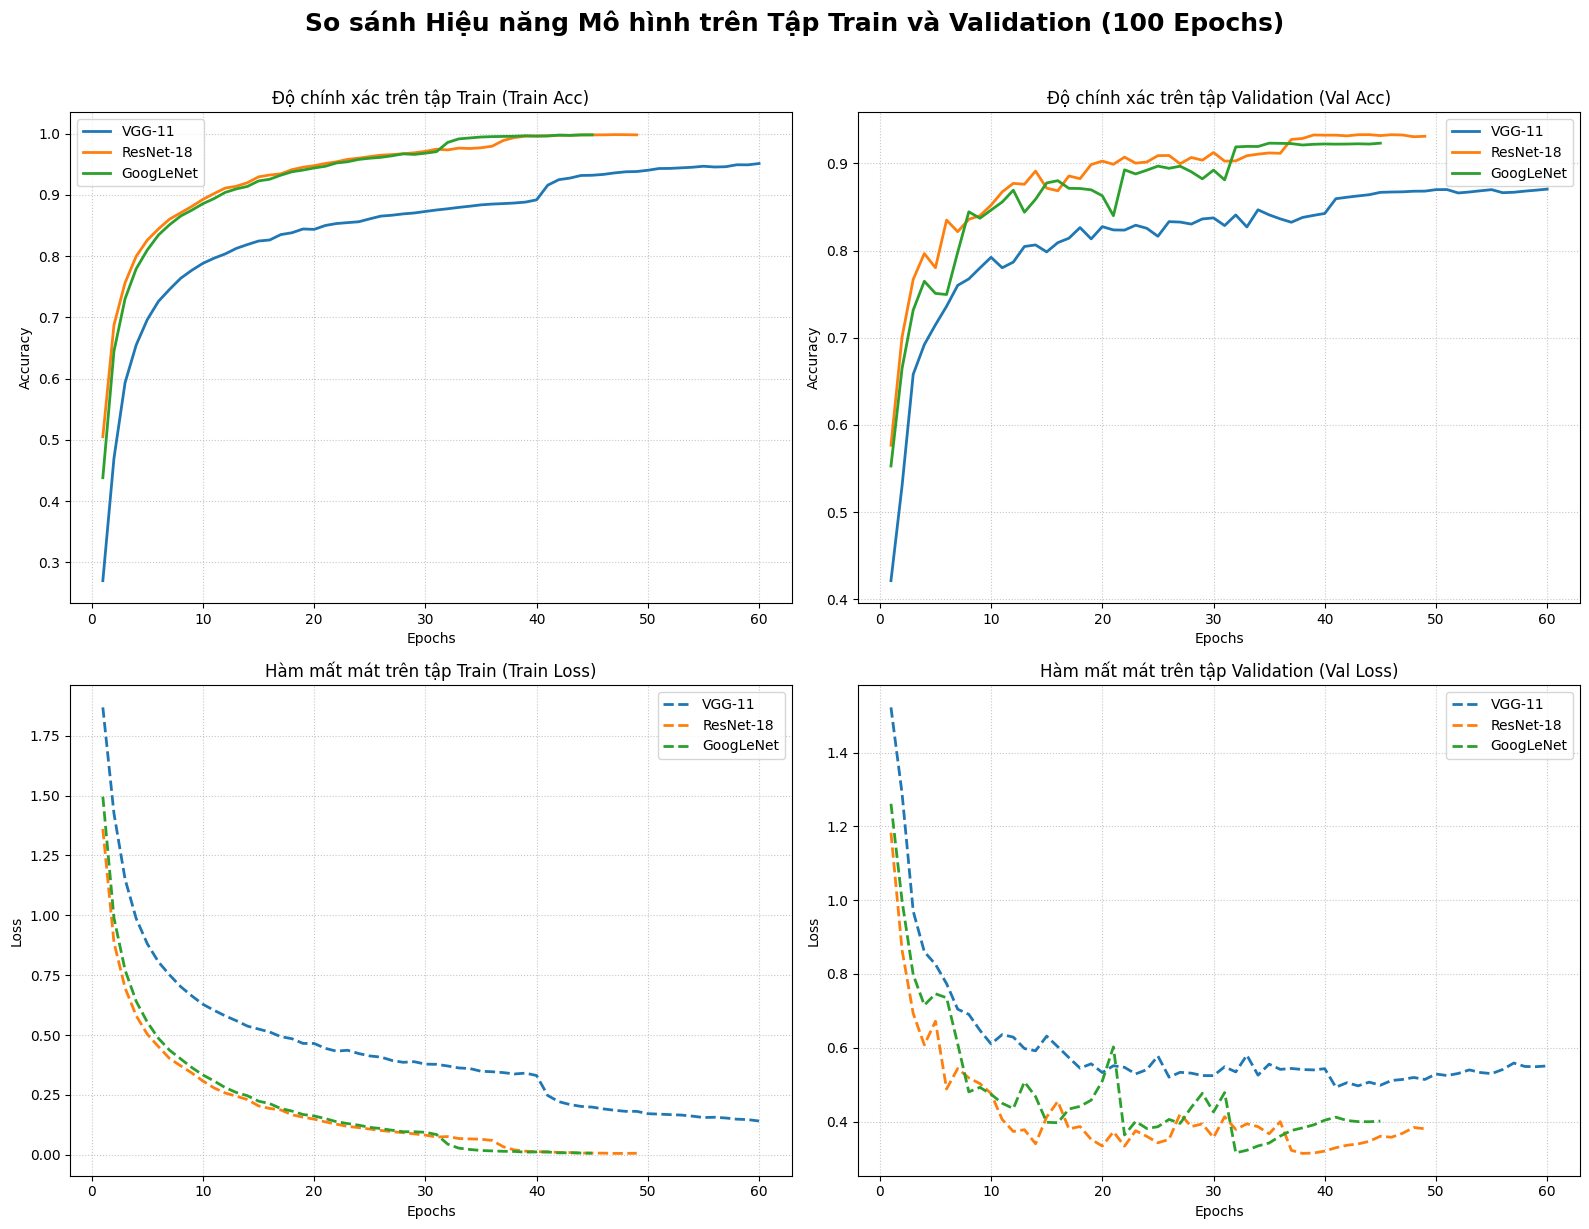

In [ ]:
import matplotlib.pyplot as plt

# Thiết lập một khung hình lớn chứa lưới 2x2 (4 biểu đồ)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))
fig.suptitle('So sánh Hiệu năng Mô hình trên Tập Train và Validation (100 Epochs)', fontsize=18, fontweight='bold', y=1.02)

# Lấy danh sách tên các mô hình từ kết quả đã train
models_name = list(results.keys())

# ==========================================
# 1. BIỂU ĐỒ TRAIN ACCURACY (Góc trên trái)
# ==========================================
ax1 = axes[0, 0]
for name in models_name:
    data = results[name]
    epochs_range = range(1, len(data['train_acc']) + 1)
    ax1.plot(epochs_range, data['train_acc'], label=f"{name}", linewidth=2)
ax1.set_title('Độ chính xác trên tập Train (Train Acc)')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.grid(True, linestyle=':', alpha=0.7)
ax1.legend()

# ==========================================
# 2. BIỂU ĐỒ VALIDATION ACCURACY (Góc trên phải)
# ==========================================
ax2 = axes[0, 1]
for name in models_name:
    data = results[name]
    epochs_range = range(1, len(data['val_acc']) + 1)
    ax2.plot(epochs_range, data['val_acc'], label=f"{name}", linewidth=2)
ax2.set_title('Độ chính xác trên tập Validation (Val Acc)')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.grid(True, linestyle=':', alpha=0.7)
ax2.legend()

# ==========================================
# 3. BIỂU ĐỒ TRAIN LOSS (Góc dưới trái)
# ==========================================
ax3 = axes[1, 0]
for name in models_name:
    data = results[name]
    epochs_range = range(1, len(data['train_loss']) + 1)
    # Dùng nét đứt (linestyle='--') cho Loss giống biểu đồ ban đầu
    ax3.plot(epochs_range, data['train_loss'], label=f"{name}", linestyle='--', linewidth=2)
ax3.set_title('Hàm mất mát trên tập Train (Train Loss)')
ax3.set_xlabel('Epochs')
ax3.set_ylabel('Loss')
ax3.grid(True, linestyle=':', alpha=0.7)
ax3.legend()

# ==========================================
# 4. BIỂU ĐỒ VALIDATION LOSS (Góc dưới phải)
# ==========================================
ax4 = axes[1, 1]
for name in models_name:
    data = results[name]
    epochs_range = range(1, len(data['val_loss']) + 1)
    ax4.plot(epochs_range, data['val_loss'], label=f"{name}", linestyle='--', linewidth=2)
ax4.set_title('Hàm mất mát trên tập Validation (Val Loss)')
ax4.set_xlabel('Epochs')
ax4.set_ylabel('Loss')
ax4.grid(True, linestyle=':', alpha=0.7)
ax4.legend()

# Căn chỉnh lại khoảng cách giữa các đồ thị và hiển thị
plt.tight_layout()
plt.show()